# Trening MiniUNet ze stratą BCE + soft Dice

Sprawdzamy, jak dodanie soft Dice do BCE wpływa na segmentację. Trenujemy świeży MiniUNet w tych samych warunkach co w notebooku 05, z osobnym checkpointem.

Korzystamy z zapisanej listy przekrojów i podziału pacjentów. W treningu jest **2714 przekrojów**, a w walidacji **615**. Obie części obejmują również pary oznaczone jako `anomaly_candidate`. Zbiór testowy pozostaje do końcowej oceny.

Przebieg obejmuje **15 epok**. Używamy ziarna 42, paczek po 4 przekroje i optymalizatora Adam z `lr=1e-3`. Aby powtórzyć eksperyment, zrestartuj kernel **Python (inzynierka)** i wykonaj komórki od góry. Pętla zapisze checkpoint bieżącego przebiegu pod podaną ścieżką.

## 1. Biblioteki, ścieżki i inicjalizacja

Ścieżki wyznaczamy względem katalogu projektu lub katalogu nadrzędnego do `notebooks/`. Importujemy MiniUNet z `src/models.py` i ustawiamy ziarno PyTorch przed utworzeniem wag.

In [2]:
from pathlib import Path
import sys

import torch
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(project_root)

from src.models import MiniUNet

C:\Users\ci3nk\Desktop\inzynierka


In [3]:
seed = 42
torch.manual_seed(seed)
model = MiniUNet()
print(model)

MiniUNet(
  (encoder): DoubleConv(
    (layers): Sequential(
      (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): DoubleConv(
    (layers): Sequential(
      (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
    )
  )
  (upconv): ConvTranspose2d(16, 8, kernel_size=(2, 2), stride=(2, 2))
  (decoder): DoubleConv(
    (layers): Sequential(
      (0): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
    )
  )
  (head): Conv2d(8, 1, kernel_size=(1, 1), stride=(1, 1))
)


## 2. Metadane i podział pacjentów

Łączymy `pairs.csv` i `splits.csv` po `patient_id`. `validate="many_to_one"` sprawdza, czy wielu przekrojom pacjenta odpowiada co najwyżej jeden przydział. Wydruki pokazują liczebności podziału oraz kandydatów do przeglądu w treningu i walidacji.

In [8]:
pairs_df = pd.read_csv(project_root / "data" / "metadata" / "pairs.csv")
splits_df = pd.read_csv(project_root / "data" / "splits" / "splits.csv")

print(pairs_df.shape, splits_df.shape)

pairs_with_split = pairs_df.merge(right=splits_df, on="patient_id", how="left", validate="many_to_one")
print(pairs_with_split.shape)
print(pairs_with_split["split"].value_counts(dropna=False))

train_df = pairs_with_split[pairs_with_split["split"] == "train"].copy()
val_df = pairs_with_split[pairs_with_split["split"] == "val"].copy()
print(len(train_df), train_df["anomaly_candidate"].sum())
print(len(val_df), val_df["anomaly_candidate"].sum())

(3929, 7) (110, 2)


(3929, 8)
split
train    2714
val       615
test      600
Name: count, dtype: int64


2714 202
615 58


## 3. Preprocessing, Dataset i DataLoadery

`MRIDataset` odczytuje parę TIFF na żądanie. Obraz ma układ `(3, 256, 256)` i wartości w `[0, 1]`. Maska ma kształt `(1, 256, 256)` i wartości 0 lub 1. Podgląd pojedynczej pary sprawdza kształty i typy.

Generator z ziarnem 42 kontroluje tasowanie treningu. Loader walidacyjny zachowuje kolejność. Ostatnia paczka może zawierać mniej niż cztery próbki.

In [9]:
def preprocess_pair(image, mask):
    image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    mask_tensor = torch.from_numpy(mask > 0).float().unsqueeze(0)

    return (image_tensor, mask_tensor)

class MRIDataset(Dataset):
    def __init__(self, pairs_df, project_root):
        self.pairs_df = pairs_df
        self.project_root = project_root

    def __len__(self):
        return self.pairs_df.shape[0]

    def __getitem__(self, index):
        row = self.pairs_df.iloc[index]
        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]
        return preprocess_pair(tifffile.imread(image_path), tifffile.imread(mask_path))

In [11]:
train_dataset = MRIDataset(train_df, project_root)
val_dataset = MRIDataset(val_df, project_root)

image, mask = train_dataset[0]

print(len(train_dataset), len(val_dataset))
print(image.shape, image.dtype)
print(mask.shape, mask.dtype)
print(mask.unique())

2714 615
torch.Size([3, 256, 256]) torch.float32
torch.Size([1, 256, 256]) torch.float32
tensor([0.])


In [13]:
train_generator = torch.Generator()
train_generator.manual_seed(seed)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print(len(train_loader), len(val_loader))

679 154


## 4. Urządzenie, funkcja straty i optymalizator

Przenosimy model na CUDA, gdy jest dostępna, lub na CPU. Tworzymy Adama dla parametrów modelu na wybranym urządzeniu.

BCE dostaje surowe logity. Soft Dice używa prawdopodobieństw po sigmoidzie i liczy nakładanie z maską dla każdego przekroju. Iloczyn prawdopodobieństw i maski zastępuje logiczne przecięcie. Stała `eps` wygładza iloraz. Sumujemy BCE i `1 - mean(soft Dice)`.

In [14]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("wybrano cuda")
else:
    device = torch.device("cpu")
    print("wybrano cpu")

model = model.to(device)
print(next(model.parameters()).device)

wybrano cuda
cuda:0


In [16]:
def soft_dice_loss(logits, targets, eps=1e-5):
    p = torch.sigmoid(logits)

    num = 2*(p*targets).sum(dim=(1, 2, 3)) + eps
    den = p.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + eps

    return 1 - (num/den).mean()

bce_criterion = torch.nn.BCEWithLogitsLoss()

def bce_dice_loss(logits, targets):
    bce = bce_criterion(logits, targets)
    soft_dice = soft_dice_loss(logits, targets)

    return bce + soft_dice

In [17]:
criterion = bce_dice_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## 5. Trening jednej epoki

W trybie `train()` zerujemy gradienty, obliczamy logity i stratę, wykonujemy `backward()`, a potem aktualizujemy wagi przez `optimizer.step()`. Przy średniej straty ważymy wynik każdej paczki jej faktyczną liczebnością.

In [18]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    n_samples = 0
    
    for images, masks in loader:
        
        images = images.to(device)
        masks = masks.to(device)
        
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.shape[0]
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples

## 6. Walidacja i Dice

`eval()` ustawia tryb oceny, a `no_grad()` wyłącza zapisywanie grafu gradientów. Sigmoid i próg `> 0.5` dają maskę binarną do obliczenia Dice dla każdego przekroju. Dwie puste maski dają 1, a tylko jedna pusta maska daje 0.

Raportujemy średnią dla wszystkich przekrojów oraz osobno dla przekrojów z oznaczeniem i z pustym wzorcem. Ten podział pozwala sprawdzić, czy wysoki wynik ogólny wynika z trafnego przewidywania pustych masek.

In [19]:
def dice_per_sample(predictions, targets):
    targets_logic = targets > 0

    targets_sum = targets_logic.sum(dim=(1, 2, 3))
    predictions_sum = predictions.sum(dim=(1, 2, 3))
    intersection = (targets_logic & predictions).sum(dim=(1, 2, 3))

    denominator = targets_sum + predictions_sum

    return torch.where(
        denominator == 0,
        1.0,
        2 * intersection / denominator.clamp_min(1)
    )

In [20]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    n_samples = 0
    total_dice = 0.0
    total_dice_annotated = 0.0
    total_dice_empty = 0.0
    n_annotated = 0
    n_empty = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            loss = criterion(logits, masks)

            predictions = torch.sigmoid(logits) > 0.5
            dice_scores = dice_per_sample(predictions, masks)
            has_annotation = masks.sum(dim=(1, 2, 3)) > 0

            batch_size = images.shape[0]
            total_loss += loss.item() * batch_size

            n_samples += batch_size
            n_annotated += has_annotation.sum().item()
            n_empty += (~has_annotation).sum().item()

            total_dice += dice_scores.sum().item()
            total_dice_annotated += dice_scores[has_annotation].sum().item()
            total_dice_empty += dice_scores[~has_annotation].sum().item()

    assert n_annotated + n_empty == n_samples

    return {
        "loss": total_loss / n_samples,
        "dice": total_dice / n_samples,
        "dice_annotated": total_dice_annotated / n_annotated,
        "dice_empty": total_dice_empty / n_empty
    }

## 7. Przebieg treningu i zapis checkpointu

Po każdej epoce zapisujemy metryki w `history`. Checkpoint aktualizujemy przy wzroście walidacyjnego `dice_annotated`. Zapis zawiera numer epoki, wagi modelu, stan Adama, historię do chwili zapisu i użyte ziarno.

Checkpoint zapisujemy jako `miniunet_bce_dice_best.pt` w `outputs/checkpoints/`.

In [21]:
num_epochs = 15
history = []
best_val_dice = -float("inf")

best_checkpoint_path = (
    project_root / "outputs" / "checkpoints" / "miniunet_bce_dice_best.pt"
)
best_checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

In [22]:
for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = validate_one_epoch(model, val_loader, criterion, device)
    history.append(
        {"epoch": epoch, "train_loss": train_loss, **val_metrics}
    )
    
    current_dice = val_metrics["dice_annotated"]
    
    if current_dice > best_val_dice:
        new_checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "seed": seed
        }
        
        torch.save(new_checkpoint, best_checkpoint_path)
        best_val_dice = current_dice
        print(f"Zapisano najlepszy model: epoka {epoch}, Dice={current_dice:.4f}")
        
    print("\nEpoch: ", epoch)
    print("train loss: ", train_loss)
    print("val metrics: ", val_metrics)

Zapisano najlepszy model: epoka 1, Dice=0.2845

Epoch:  1
train loss:  0.9971211898300519
val metrics:  {'loss': 0.9797880973273176, 'dice': 0.5465800828868296, 'dice_annotated': 0.28452013049400965, 'dice_empty': 0.7097625329815304}
Zapisano najlepszy model: epoka 2, Dice=0.2898

Epoch:  2
train loss:  0.8753728088246784
val metrics:  {'loss': 0.987426175916098, 'dice': 0.5437360908926987, 'dice_annotated': 0.28982074470338176, 'dice_empty': 0.7018469656992085}

Epoch:  3
train loss:  0.86915440623516
val metrics:  {'loss': 0.9816812070404611, 'dice': 0.5512040104444434, 'dice_annotated': 0.27114604451393676, 'dice_empty': 0.7255936675461742}

Epoch:  4
train loss:  0.8669895358004812
val metrics:  {'loss': 0.9792489270853802, 'dice': 0.5547846192993768, 'dice_annotated': 0.2889514439186807, 'dice_empty': 0.7203166226912929}

Epoch:  5
train loss:  0.8631650695224501
val metrics:  {'loss': 0.9855509966369567, 'dice': 0.578991821602108, 'dice_annotated': 0.284237163046659, 'dice_empty'

## 8. Historia i ponowna ocena wybranego modelu

Tabela pokazuje średnią stratę treningową, stratę walidacyjną oraz trzy wyniki Dice na walidacji. Obie kolumny straty zawierają sumę BCE i soft Dice.

Wczytujemy checkpoint na CPU i odtwarzamy wagi w osobnej instancji MiniUNet. Ponowna ocena na walidacji sprawdza, czy zapis odpowiada wybranej epoce. Pionowa linia na wykresach wskazuje numer zapisanej epoki.

In [23]:
pd.DataFrame(history)

,epoch,train_loss,loss,dice,dice_annotated,dice_empty
0,1,0.997121,0.979788,0.546580,0.284520,0.709763
1,2,0.875373,0.987426,0.543736,0.289821,0.701847
2,3,0.869154,0.981681,0.551204,0.271146,0.725594
3,4,0.866990,0.979249,0.554785,0.288951,0.720317
4,5,0.863165,0.985551,0.578992,0.284237,0.762533
5,6,0.861476,0.974958,0.586638,0.282976,0.775726
6,7,0.857746,0.964761,0.543621,0.310706,0.688654
7,8,0.856399,0.962109,0.555833,0.325582,0.699208
8,9,0.853855,0.956638,0.478267,0.335315,0.567282
9,10,0.852425,0.951275,0.517085,0.322064,0.638522


In [30]:
best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print(best_checkpoint["epoch"])
best_model = MiniUNet()
best_model.load_state_dict(best_checkpoint["model_state_dict"])
best_model.to(device)
best_val_metrics = validate_one_epoch(best_model, val_loader, criterion, device)
print(best_val_metrics)

9
{'loss': 0.9566383549837563, 'dice': 0.4782670408729615, 'dice_annotated': 0.3353145356779381, 'dice_empty': 0.5672823218997362}


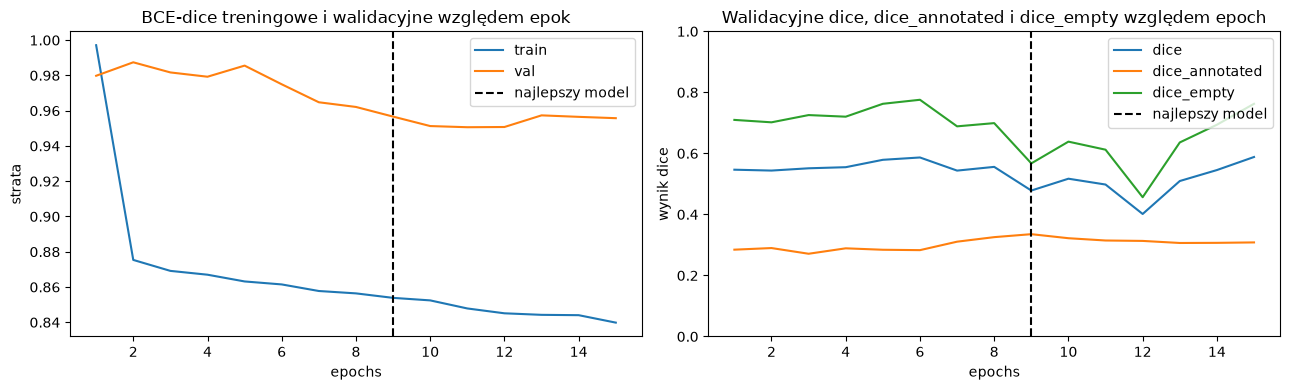

In [31]:
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="train"
)

ax[0].plot(
    history_df["epoch"],
    history_df["loss"],
    label="val"
)
ax[0].axvline(
    best_checkpoint["epoch"],
    color="black",
    linestyle="--",
    label="najlepszy model"
)
ax[0].set_xlabel("epochs")
ax[0].set_ylabel("strata")
ax[0].set_title("BCE-dice treningowe i walidacyjne względem epok")
ax[0].legend()

ax[1].plot(
    history_df["epoch"],
    history_df["dice"],
    label="dice"
)

ax[1].plot(
    history_df["epoch"],
    history_df["dice_annotated"],
    label="dice_annotated"
)

ax[1].plot(
    history_df["epoch"],
    history_df["dice_empty"],
    label="dice_empty"
)

ax[1].axvline(
    best_checkpoint["epoch"],
    color="black",
    linestyle="--",
    label="najlepszy model"
)
ax[1].set_xlabel("epochs")
ax[1].set_ylabel("wynik dice")
ax[1].set_ylim(0, 1)
ax[1].set_title("Walidacyjne dice, dice_annotated i dice_empty względem epoch")
ax[1].legend()

plt.tight_layout()
plt.show()

## 9. Diagnostyka po ostatniej epoce

Oceniamy model z pamięci po ostatniej epoce na treningu przy stałych wagach. Odpowiada mu ostatni wiersz tabeli walidacyjnej.

Dla pierwszego przekroju walidacyjnego z oznaczeniem pokazujemy FLAIR, maskę wzorcową, mapę prawdopodobieństw i maskę po progowaniu. To przykład jakościowy, uzupełniający metryki z całej walidacji.

In [25]:
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

train_eval_metrics = validate_one_epoch(model, train_eval_loader, criterion, device)
print(train_eval_metrics)

{'loss': 0.8432288378938296, 'dice': 0.6581055586457571, 'dice_annotated': 0.5695211350990544, 'dice_empty': 0.7036830357142857}


In [27]:
example_df = val_df[val_df["has_annotation"]].head(1)
example_dataset = MRIDataset(example_df, project_root)
image, mask = example_dataset[0]

model.eval()

with torch.no_grad():
    image_gpu = image.unsqueeze(0).to(device)
    logits = model(image_gpu)
    probabilities = torch.sigmoid(logits).to("cpu") 
    predicted_mask = (probabilities > 0.5).to("cpu")

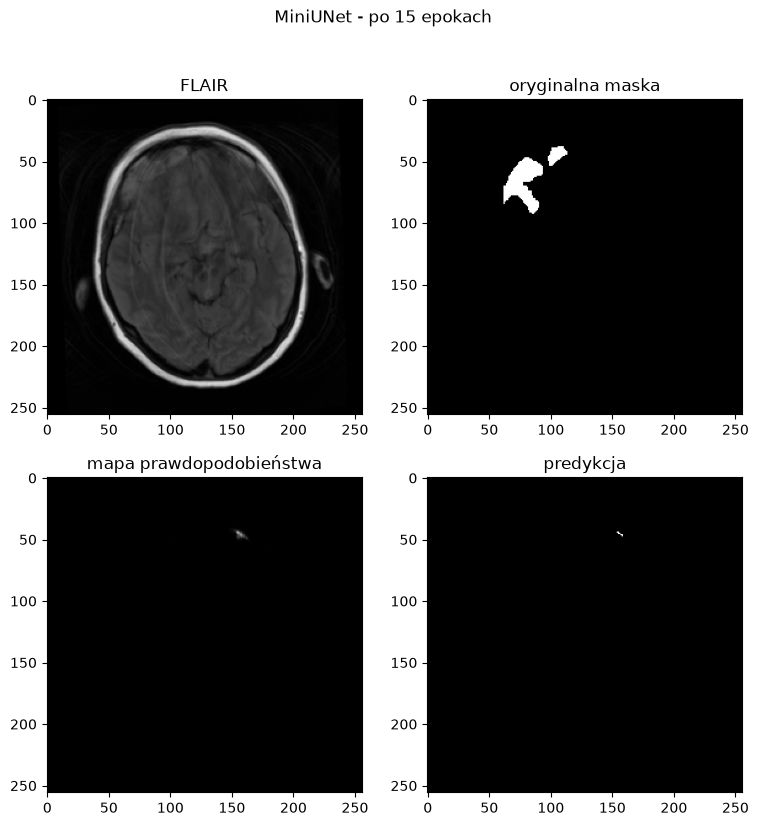

In [28]:
fig, ax = plt.subplots(2, 2, figsize=(9, 9))
fig.suptitle(f"MiniUNet - po {history[-1]['epoch']} epokach")

ax[0, 0].imshow(image[1], cmap="gray", vmax=1, vmin=0)
ax[0, 0].set_title("FLAIR")
ax[0, 1].imshow(mask[0], cmap="gray", vmax=1, vmin=0)
ax[0, 1].set_title("oryginalna maska")
ax[1, 0].imshow(probabilities[0, 0], cmap="gray", vmax=1, vmin=0)
ax[1, 0].set_title("mapa prawdopodobieństwa")
ax[1, 1].imshow(predicted_mask[0, 0], cmap="gray", vmax=1, vmin=0)
ax[1, 1].set_title("predykcja")
plt.show()

## Wnioski z zapisanego przebiegu

Najwyższy walidacyjny Dice przekrojów z oznaczeniem uzyskano w **epoce 9**. W tabeli porównujemy checkpointy wybrane według tej samej metryki.

| Walidacja | BCE (epoka 14) | BCE + soft Dice (epoka 9) |
| --- | ---: | ---: |
| Dice z oznaczeniem | 0,2455 | 0,3353 |
| Dice pustych masek | 0,8602 | 0,5673 |
| Dice ogólny | 0,6243 | 0,4783 |

W tym przebiegu dodanie soft Dice poprawiło dopasowanie oznaczonych obszarów. Jednocześnie na przekrojach z pustym wzorcem model częściej przewidywał co najmniej jeden piksel zmiany. Porównujemy wspólne metryki Dice, ponieważ wartości straty pochodzą z różnych funkcji. Kolejny eksperyment dotyczy większego U-Neta.